# BRANCH walkthrough

This notebook reproduces the core of the paper in a few minutes: the lemma behind the query strategy, one session of the agent on a real comparison, a small version of the benchmark, and the figures of the paper. The full benchmark is `bash reproduce.sh` (several hours).

Data: Life Cycle Inventory database of the Swiss Federal Administration, BAFU:2026. The factors are extracted locally from openLCA (`bash reproduce.sh data`) and never redistributed. Without them the notebook runs on **illustrative demo numbers**, and says so below.

In [1]:
import os, sys
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, ROOT); os.chdir(ROOT)
import numpy as np, pandas as pd
from branch.real_cases import load_factors
from branch.demo_factors import demo_factors
try:
    factors, DEMO = load_factors(), False
except FileNotFoundError:
    factors, DEMO = demo_factors(), True
print('DEMO NUMBERS, not real inventory data' if DEMO else 'Real factors: ' + os.path.relpath(factors['path'], ROOT))

Real factors: data/factors/bafu2026_EF_3_1_Method_adapted_.json


## 1. The lemma

BRANCH scores an open choice $j$ by the expected reduction of $p(1-p)$, with $p = P(I_A < I_B)$. Proposition 1: this equals $p(1-p)\,S_j(D)$, the first order Sobol index of the verdict $D = 1\{I_A < I_B\}$. Below, the score and $p(1-p)S_j(D)$ computed directly agree up to the Monte Carlo gap.

In [2]:
from branch.cases import toy_packaging
from branch.montecarlo import State, p_a_lower
from branch.query import STRATEGIES
m = toy_packaging(); st = State(m, m.sample(200_000, seed=11))
scores = STRATEGIES['decision_flip'](st, np.random.default_rng(0))
rows = []
for name in st.open:
    d, w = st.conditional_deltas(name)
    pk = (d < 0).mean(axis=1); pbar = float((w * pk).sum())
    s_j = float((w * (pk - pbar) ** 2).sum()) / (pbar * (1 - pbar))
    rows.append((name, scores[name], pbar * (1 - pbar) * s_j, s_j))
pd.DataFrame(rows, columns=['choice', 'decision flip score', 'p(1-p) S_j(D)', 'S_j(D)']).sort_values('decision flip score', ascending=False).round(5)

,choice,decision flip score,p(1-p) S_j(D),S_j(D)
3,glass_trips,0.02322,0.01789,0.14242
4,glass_km,0.01385,0.01357,0.10388
2,pet_eol,0.00992,0.01055,0.08020
1,pet_recycled,0.00613,0.00634,0.04834
0,pet_dataset,0.00065,0.00116,0.00884
6,grid_ef,0.00064,0.00027,0.00206
5,wash_kwh,0.00051,0.00076,0.00583
7,capital_goods,0.00025,0.00054,0.00410


Proposition 2: the literal loss $\min(p, 1-p)$ scores every question zero when no single answer can carry $p$ across 1/2, so the agent stalls. With the total probability estimator this is exact:

In [3]:
from tests.test_lemma import _leaning_model
lm = _leaning_model(); s2 = State(lm, lm.sample(100_000, seed=3))
print('p =', round(float(p_a_lower(s2.delta)), 4))
print('min(p,1-p) scores:', STRATEGIES['decision_flip_min_tp'](s2, np.random.default_rng(0)))
print('p(1-p) scores:    ', STRATEGIES['decision_flip_tp'](s2, np.random.default_rng(0)))

p = 0.005
min(p,1-p) scores: {'x0': 0.0, 'x1': 0.0}
p(1-p) scores:     {'x0': 1.140623999999952e-06, 'x1': 3.819239999999996e-05}


## 2. One session: single use PET against refillable glass in Portugal

A simulated expert holds a hidden true value for every choice and answers each question with it. The agent asks three questions per round and stops when the verdict is wrong with probability below 2.5%, the setting of the web application.

In [4]:
from branch.real_cases import compare
from branch.cases import draw_truth
from branch.agent import run_agent
model = compare('pet_bottle_1l', 'glass_refillable_1l', region='PT', factors=factors)
truth = draw_truth(model, seed=1)
r = run_agent(model, lambda n: truth[n], batch_size=3, tau=0.025, seed=1, truth=truth)
print(len(model.choices), 'open choices;', r['questions'], 'asked:', r['asked'])
print('verdict:', r['verdict'], '| P(wrong) =', round(r['p_flip'], 4), '| agrees with expert:', r['correct'])

14 open choices; 9 asked: ['distribution_km', 'pet.bottle.mass_g', 'glass.trips', 'glass.bottle.mass_g', 'glass.wash_heat_mj', 'pet.pet.recycled_content', 'pet.pet.incineration_share', 'pet.pet.recycling_rate', 'pet.pet.dataset']
verdict: PET single use < Refillable glass | P(wrong) = 0.0 | agrees with expert: True


What each question looks like in the web application, with its plain language help:

In [5]:
from branch import webapp
from branch.agent import Session
s = Session(model, batch_size=3, tau=0.025, seed=1)
v = webapp.question_view(s)
print(v['text']); print('Why it matters:', v['why']); print('Where to find it:', v['where'])

How far does the truck travel from the bottling plant to the shops, one way (km)?
Why it matters: Every kilometre the truck drives adds fuel use, and heavier packaging makes it count more.
Where to find it: Your logistics provider or delivery notes give the distance from your plant to the main customers; use a typical one way distance.


## 3. A small benchmark

Same comparison, 10 seeds, every strategy. The paper uses 18 cases and 30 seeds per cell.

In [6]:
strategies = ['decision_flip', 'sobol', 'decision_flip_min', 'entropy', 'margin', 'random']
res = []
for seed in range(10):
    t = draw_truth(model, seed)
    for sname in strategies:
        out = run_agent(model, lambda n: t[n], strategy=sname, batch_size=3, tau=0.025,
                        n_samples=10_000, seed=seed, truth=t)
        res.append((sname, seed, out['questions'], out['correct']))
df = pd.DataFrame(res, columns=['strategy', 'seed', 'questions', 'correct'])
df.groupby('strategy').agg(mean_questions=('questions', 'mean'), correct=('correct', 'mean')).sort_values('mean_questions').round(2)

,mean_questions,correct
strategy,,
sobol,6.9,1.0
decision_flip,7.2,1.0
decision_flip_min,7.2,1.0
entropy,10.3,1.0
margin,10.3,1.0
random,12.3,1.0


## 4. Figures and tables of the paper

Built from `results/` when the benchmark was rerun, else from the summaries committed in `paper/data/`.

In [7]:
import subprocess
print(subprocess.run([sys.executable, 'experiments/paper_assets.py'], capture_output=True, text=True).stdout)
pd.read_csv('paper/data/benchmark_tau0.025.csv').query('batch_size == 3')[['strategy', 'q_mean', 'wrong_when_certified_pct', 'p_vs_decision_flip']]

Playwright not installed: keeping the committed overview.pdf
paper assets in paper/figures and paper/tables



,strategy,q_mean,wrong_when_certified_pct,p_vs_decision_flip
20,decision_entropy,2.750000,0.370370,1.000000
21,decision_flip,2.750000,0.370370,NaN
22,decision_flip_tp,2.772222,0.370370,1.000000
23,sobol,2.777778,0.370370,1.000000
24,decision_flip_min,2.964815,0.370370,0.187500
25,decision_flip_min_tp,3.638889,0.370370,0.008789
26,entropy,4.501852,0.185185,0.008789
27,least_confident,4.501852,0.185185,0.008789
28,margin,4.512963,0.185185,0.008789
29,random,5.783333,0.185185,0.008789


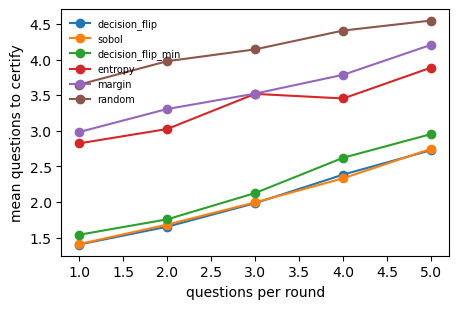

In [8]:
import matplotlib.pyplot as plt
d = pd.read_csv('paper/data/benchmark.csv')
fig, ax = plt.subplots(figsize=(5, 3.2))
for sname in strategies:
    g = d[d.strategy == sname].sort_values('batch_size')
    ax.plot(g.batch_size, g.q_mean, marker='o', label=sname)
ax.set_xlabel('questions per round'); ax.set_ylabel('mean questions to certify')
ax.legend(fontsize=7, frameon=False); plt.show()